# Помогает ли реклама получать больше покупок?

Учебный анализ Marketing A/B Testing с Kaggle. Одна строка — один пользователь. Сравниваем опубликованные группы `ad` и `psa`, считаем размер различия и неопределённость, затем формулируем следующий шаг для бизнеса.

Первичный протокол рандомизации, окно наблюдения и расходы отсутствуют. Поэтому вывод о причинном эффекте условен, а ROI не рассчитывается. Используется локальный файл marketing_AB.csv. Подготовка: python scripts/download_data.py --csv путь/к/marketing_AB.csv.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.data import load_data
from src.analysis import analyze
from src.statistics import required_sample, aa_simulation
import pandas as pd
from IPython.display import display, Image
frame, quality = load_data()
print(f'Пользователей: {len(frame):,}')
print('Колонки:', ', '.join(frame.columns))
print('Пропусков:', int(frame.isna().sum().sum()))
print('Повторяющихся ID:', int(frame.user_id.duplicated().sum()))

Пользователей: 588,101
Колонки: user_id, test_group, converted, total_ads, most_ads_day, most_ads_hour
Пропусков: 0
Повторяющихся ID: 0


## Что будем измерять

Бизнес-вопрос: отличается ли вероятность покупки у пользователей рекламной группы от PSA? Основная метрика — число пользователей с `converted=True`, делённое на число пользователей группы. Одна строка не является одним рекламным показом.

H₀: конверсии равны. Альтернатива двусторонняя. α = 0,05. Анализ ретроспективный; это не зарегистрированный до запуска протокол эксперимента. Дни и часы показов не используются для поиска «значимого сегмента».

In [2]:
groups, effect = analyze(frame)
display(groups)
print(f"Разница: {effect['difference']*100:.3f} п.п.")
print(f"Относительное различие: {effect['relative_lift']*100:.2f}%")
print(f"95% интервал: [{effect['ci_low']*100:.3f}; {effect['ci_high']*100:.3f}] п.п.")
print(f"p-value: {effect['p_value']:.3g}")

,users,conversions,conversion_rate,ci_low,ci_high
test_group,,,,,
psa,23524,420,0.017854,0.016239,0.019627
ad,564577,14423,0.025547,0.025138,0.025961


Разница: 0.769 п.п.
Относительное различие: 43.09%
95% интервал: [0.587; 0.936] п.п.
p-value: 1.71e-13


## Как читать результат

Процентный пункт — разность процентов; относительный рост — отношение этой разности к контрольной конверсии. Это разные величины.

Для сравнения используем z-тест двух долей. Для интервала разницы — метод Newcombe на основе интервалов Wilson. Наблюдений и успешных исходов достаточно для нормальной аппроксимации; предположение о независимости и назначении групп нужно подтвердить по первичным документам.

`p-value` не является вероятностью истинности H₀. 95% доверительный интервал описывает процедуру оценивания при повторении, а не вероятность попадания уже фиксированного параметра в конкретный интервал.

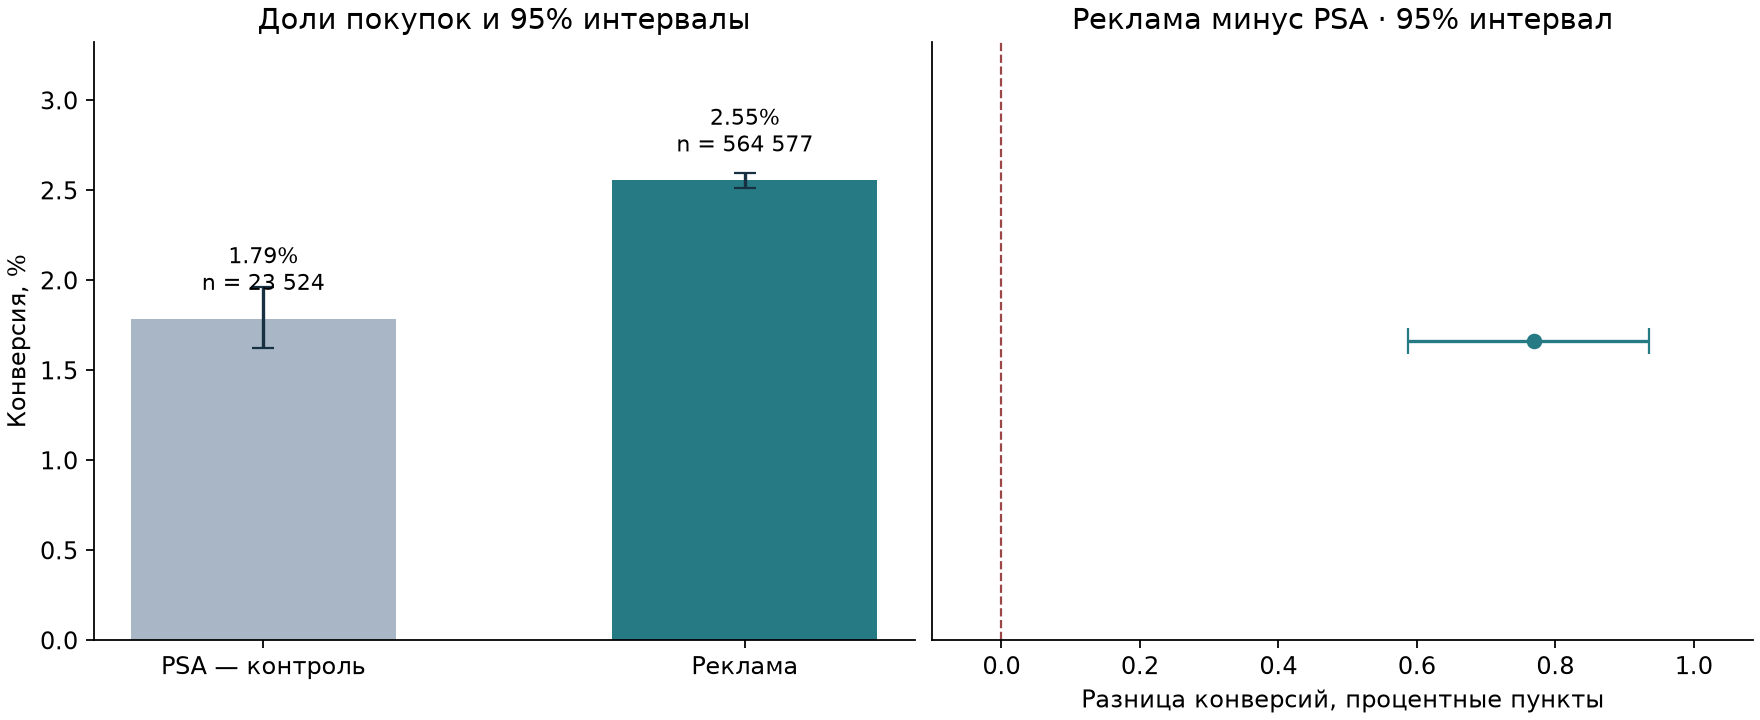

In [3]:
display(Image(filename=str(ROOT/'figures/conversion-comparison.png')))

## Проверка статистического метода

Генерируем искусственные группы с одинаковой вероятностью покупки. Проверяем, как часто тест ошибочно находит отличие. Это симуляция для проверки кода, не A/A-эксперимент над исходными пользователями.

,repeats,users_per_group,assumed_rate,seed,alpha,false_positive_rate,rate_ci
0,10000,10000,0.02,2026,0.05,0.053,"[0.048778160614320124, 0.05756513392906473]"


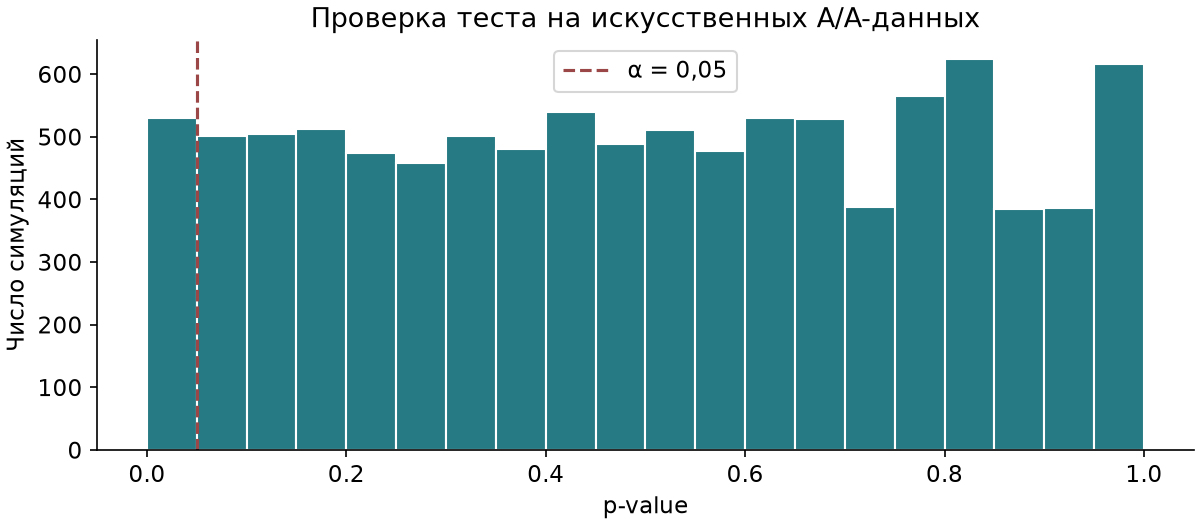

In [4]:
aa, _ = aa_simulation()
display(pd.DataFrame([aa]).drop(columns=['note']))
display(Image(filename=str(ROOT/'figures/aa-calibration.png')))

## Планирование следующего эксперимента

Отдельный иллюстративный сценарий: базовая конверсия 2%, минимальный интересующий эффект +0,5 п.п., мощность 80%. Это допущения для будущего теста, не «наблюдаемая мощность» текущего. Сравним равное распределение с соотношением размеров групп в опубликованном наборе.

In [5]:
ratio = groups.loc['ad', 'users'] / groups.loc['psa', 'users']
display(pd.DataFrame([required_sample(), required_sample(ratio=float(ratio))]).drop(columns=['note']))

,assumed_control_rate,absolute_mde,target_power,test_to_control_ratio,alpha,control_users,test_users
0,0.02,0.005,0.8,1.000000,0.05,13809,13809
1,0.02,0.005,0.8,24.000043,0.05,7463,179113


## Вывод для бизнеса

В опубликованных группах есть положительное различие конверсии. Масштабирование нельзя обосновать одним p-value: нужны стоимость контакта, маржа, подтверждение распределения и защитные метрики. Предлагаемый следующий шаг — контролируемый тест с заранее зафиксированным дизайном.

Не строим причинные выводы о частоте показов и времени суток: эти характеристики могли возникнуть после воздействия. Не называем разницу размеров групп SRM без известной плановой пропорции. Не применяем CUPED без предэкспериментальных данных.

Подробный вывод: `results/business-summary.md`. SQL и оконные функции: `sql/questions.sql`. Проверки: `python -m unittest discover -s tests -v`.